In [15]:
import pandas as pd
import numpy as np

film_sayisi = 100

data = {
    "Title": [f"Yapım {i}" for i in range(1, film_sayisi + 1)],
    "Type": np.random.choice(["Movie", "TV Show"], film_sayisi),
    "Genre": np.random.choice(["Sci-Fi", "Drama", "Comedy", "Action", "Romance", "Horror"], film_sayisi),
    "ReleaseYear": np.random.randint(1990, 2025, film_sayisi),
    "Rating": np.round(np.random.uniform(1.0, 10.0, film_sayisi), 1),
    "Duration": np.random.randint(20, 200, film_sayisi),
    "Country": np.random.choice(["USA", "UK", "Turkey", "South Korea", "Japan", "France"], film_sayisi),
    "Votes": np.random.randint(1000, 2000000, film_sayisi)
}

df = pd.DataFrame(data)

In [16]:
df.head()

,Title,Type,Genre,ReleaseYear,Rating,Duration,Country,Votes
0,Yapım 1,Movie,Action,2016,6.4,104,USA,284714
1,Yapım 2,TV Show,Action,2017,5.6,164,France,939860
2,Yapım 3,Movie,Drama,2022,7.0,157,USA,1213760
3,Yapım 4,Movie,Romance,2016,4.1,183,South Korea,663913
4,Yapım 5,Movie,Drama,1999,8.1,94,France,1529766


In [17]:
film_dizi_sayisi = df['Type'].value_counts()
farkli_tur_sayisi = df['Genre'].nunique()
ortalama_puan = df['Rating'].mean()
eksik_degerler = df.isnull().sum()

In [18]:
print(f"Film ve Dizi Sayısı  :{film_dizi_sayisi}")
print(f"Farklı Tür Sayısı     :{farkli_tur_sayisi}")
print(f"Ortalama Puan         :{ortalama_puan}")
print(f"Eksik Değerler        :{eksik_degerler}")

Film ve Dizi Sayısı  :Type
TV Show    55
Movie      45
Name: count, dtype: int64
Farklı Tür Sayısı     :6
Ortalama Puan         :5.5809999999999995
Eksik Değerler        :Title          0
Type           0
Genre          0
ReleaseYear    0
Rating         0
Duration       0
Country        0
Votes          0
dtype: int64


In [19]:
en_yuksek_puanli_10 = df.sort_values(by='Rating', ascending=False).head(10)
en_fazla_oy_alan_10 = df.sort_values(by='Votes', ascending=False).head(10)
tur_ortalama_puan = df.groupby('Genre')['Rating'].mean()

sadece_filmler = df[df['Type'] == 'Movie']
ulkelere_gore_film_sayisi = sadece_filmler['Country'].value_counts()
yillara_gore_film_sayisi = sadece_filmler['ReleaseYear'].value_counts()

print("En Yüksek Puanlı 10 Yapım:\n", en_yuksek_puanli_10, "\n")
print("En Fazla Oy Alan 10 Yapım:\n", en_fazla_oy_alan_10, "\n")
print("Türlere Göre Ortalama Puan:\n", tur_ortalama_puan,"\n" )
print("Ülkelere Göre Film Sayısı:\n", ulkelere_gore_film_sayisi, "\n")
print("Yıllara Göre Çıkan Film Sayısı:\n", yillara_gore_film_sayisi)

En Yüksek Puanlı 10 Yapım:
        Title     Type    Genre  ReleaseYear  Rating  Duration      Country  \
85  Yapım 86    Movie    Drama         2024     9.9        63       France   
14  Yapım 15  TV Show   Sci-Fi         2018     9.7       114       France   
25  Yapım 26    Movie   Sci-Fi         2012     9.5       152       Turkey   
97  Yapım 98  TV Show  Romance         1995     9.4       172          USA   
16  Yapım 17  TV Show  Romance         2007     9.3        58           UK   
34  Yapım 35  TV Show   Sci-Fi         2002     9.2        31          USA   
80  Yapım 81  TV Show   Horror         2024     9.1        58       Turkey   
31  Yapım 32  TV Show   Comedy         2024     9.0        23          USA   
44  Yapım 45    Movie   Comedy         2014     9.0        41  South Korea   
61  Yapım 62    Movie    Drama         2003     9.0        67           UK   

      Votes  
85   319869  
14    11454  
25  1590014  
97  1319579  
16   950414  
34   567058  
80  1459456  
3

In [20]:
def rating_kategorisi(puan):
    if puan <= 5.0:
        return "Düşük"
    elif puan <= 7.0:
        return "Orta"
    elif puan <= 8.5:
        return "İyi"
    else:
        return "Çok İyi"

df['RatingCategory'] = df['Rating'].apply(rating_kategorisi)

def donem_kategorisi(yil):
    if yil < 2000:
        return "Before 2000"
    elif yil <= 2010:
        return "2000-2010"
    elif yil <= 2020:
        return "2010-2020"
    else:
        return "2020+"

df['Period'] = df['ReleaseYear'].apply(donem_kategorisi)

print(df[['Rating', 'RatingCategory', 'ReleaseYear', 'Period']].head(10))

   Rating RatingCategory  ReleaseYear       Period
0     6.4           Orta         2016    2010-2020
1     5.6           Orta         2017    2010-2020
2     7.0           Orta         2022        2020+
3     4.1          Düşük         2016    2010-2020
4     8.1            İyi         1999  Before 2000
5     1.6          Düşük         2012    2010-2020
6     3.6          Düşük         2013    2010-2020
7     4.9          Düşük         2002    2000-2010
8     3.4          Düşük         2018    2010-2020
9     4.0          Düşük         2015    2010-2020


In [21]:
df.head()

,Title,Type,Genre,ReleaseYear,Rating,Duration,Country,Votes,RatingCategory,Period
0,Yapım 1,Movie,Action,2016,6.4,104,USA,284714,Orta,2010-2020
1,Yapım 2,TV Show,Action,2017,5.6,164,France,939860,Orta,2010-2020
2,Yapım 3,Movie,Drama,2022,7.0,157,USA,1213760,Orta,2020+
3,Yapım 4,Movie,Romance,2016,4.1,183,South Korea,663913,Düşük,2010-2020
4,Yapım 5,Movie,Drama,1999,8.1,94,France,1529766,İyi,Before 2000


In [22]:
istatistikler = df.groupby('Type')['Rating'].agg(['mean', 'median', 'std'])
print(istatistikler)

             mean  median       std
Type                               
Movie    5.811111     6.0  2.423204
TV Show  5.392727     5.2  2.646931


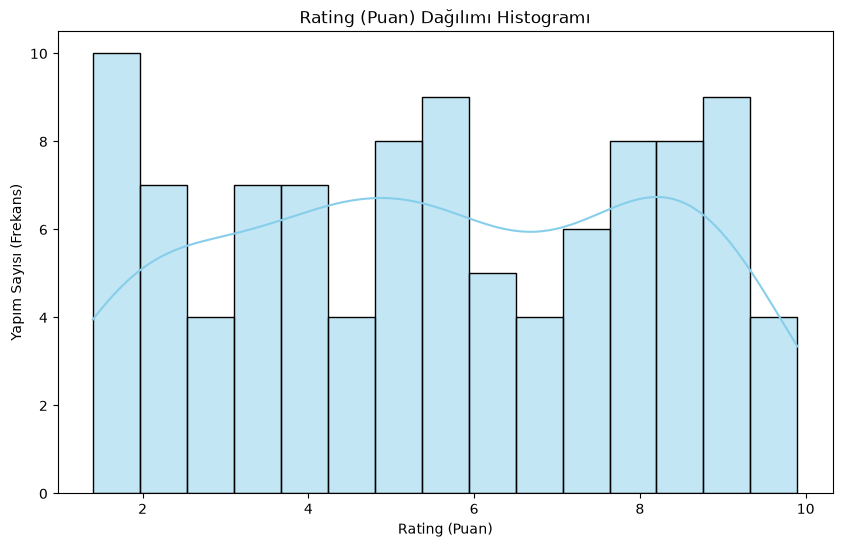

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Rating', bins=15, kde=True, color='skyblue')
plt.title("Rating (Puan) Dağılımı Histogramı")
plt.xlabel("Rating (Puan)")
plt.ylabel("Yapım Sayısı (Frekans)")
plt.show()

C:\Users\MyComputer\AppData\Local\Temp\ipykernel_14316\3903185967.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Genre', y='Rating', palette='viridis')


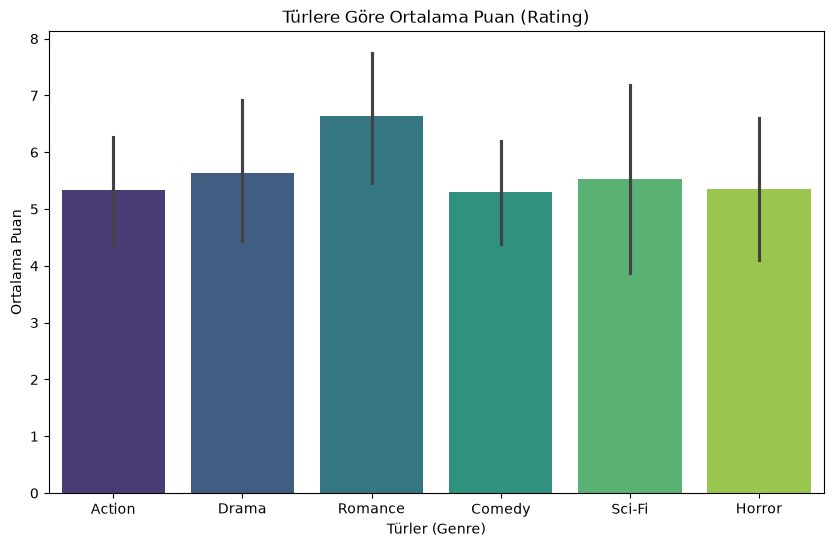

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Genre', y='Rating', palette='viridis')
plt.title("Türlere Göre Ortalama Puan (Rating)")
plt.xlabel("Türler (Genre)")
plt.ylabel("Ortalama Puan")

plt.show()

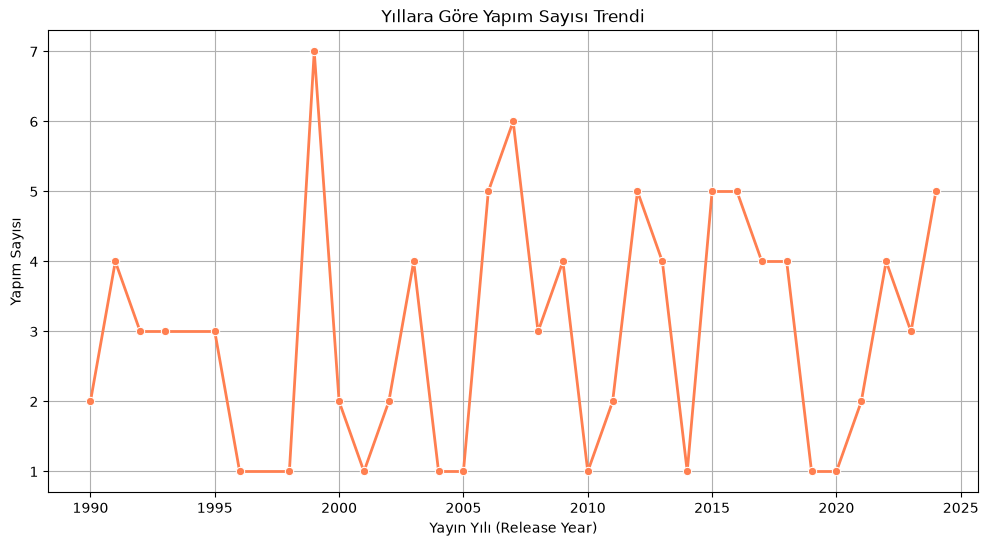

In [25]:
yillara_gore_sayi = df['ReleaseYear'].value_counts().sort_index()
plt.figure(figsize=(12, 6))
sns.lineplot(x=yillara_gore_sayi.index, y=yillara_gore_sayi.values, marker='o', color='coral', linewidth=2)
plt.title("Yıllara Göre Yapım Sayısı Trendi")
plt.xlabel("Yayın Yılı (Release Year)")
plt.ylabel("Yapım Sayısı")
plt.grid(True)
plt.show()

C:\Users\MyComputer\AppData\Local\Temp\ipykernel_14316\4153922758.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Type', y='Rating', palette='Set3')


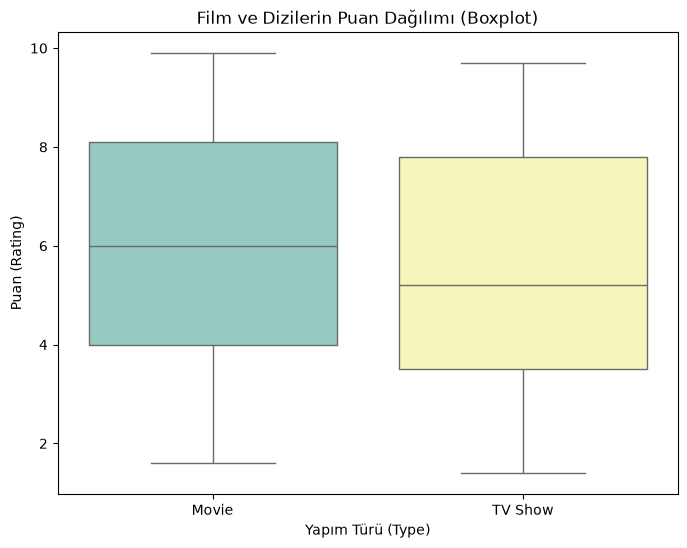

In [29]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Type', y='Rating', palette='Set3')
plt.title("Film ve Dizilerin Puan Dağılımı (Boxplot)")
plt.xlabel("Yapım Türü (Type)")
plt.ylabel("Puan (Rating)")
plt.show()

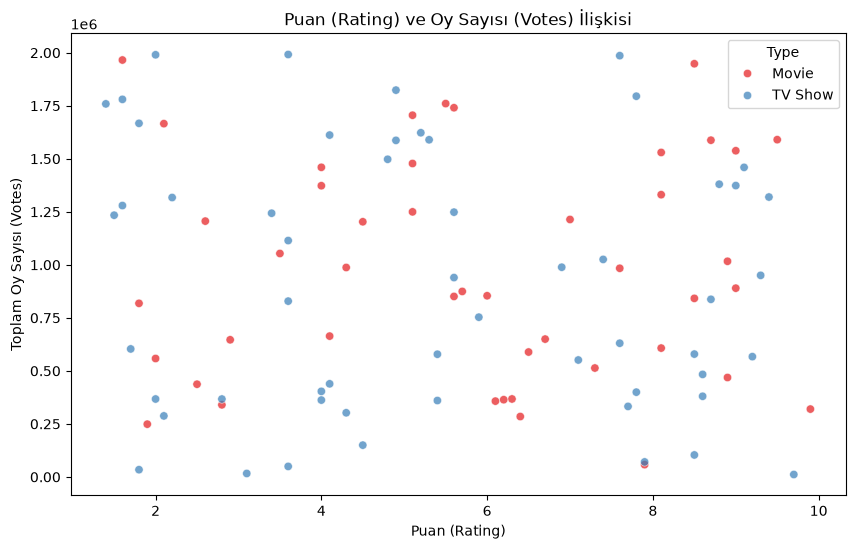

In [30]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Rating', y='Votes', hue='Type', alpha=0.7, palette='Set1')
plt.title("Puan (Rating) ve Oy Sayısı (Votes) İlişkisi")
plt.xlabel("Puan (Rating)")
plt.ylabel("Toplam Oy Sayısı (Votes)")
plt.show()

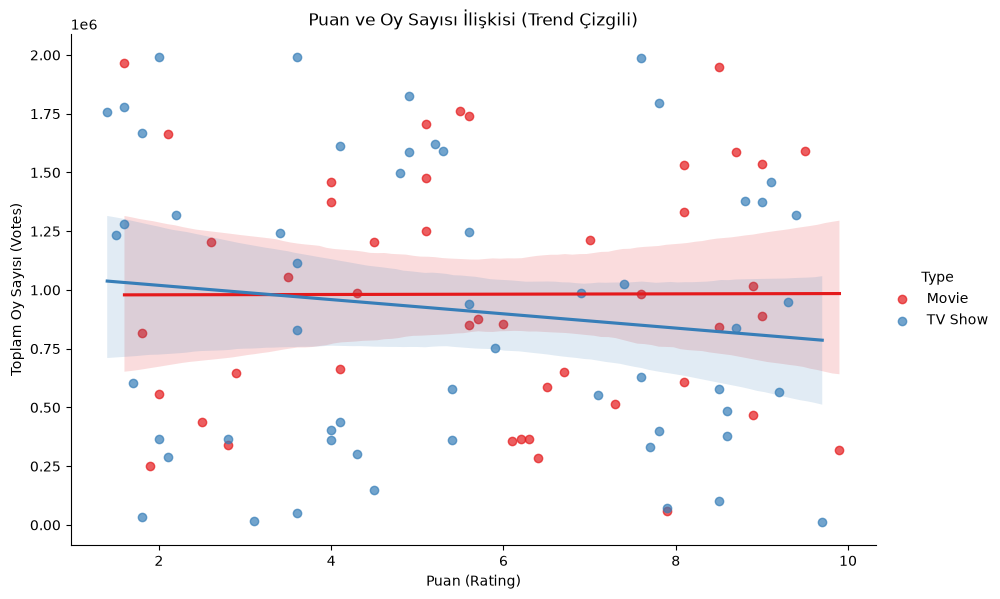

In [31]:
sns.lmplot(data=df, x='Rating', y='Votes', hue='Type', height=6, aspect=1.5, 
           palette='Set1', scatter_kws={'alpha':0.7})
plt.title("Puan ve Oy Sayısı İlişkisi (Trend Çizgili)")
plt.xlabel("Puan (Rating)")
plt.ylabel("Toplam Oy Sayısı (Votes)")

plt.show()